<a href="https://colab.research.google.com/github/Arica80/FTIR-Functional-Group-Classification/blob/main/notebooks/FTIR_HOG_SVM_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/Arica80/FTIR-Functional-Group-Classification.git
%cd FTIR-Functional-Group-Classification
!pip install -r requirements.txt
!python scripts/audit_inventory.py

Cloning into 'FTIR-Functional-Group-Classification'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 14 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 58.15 KiB | 5.29 MiB/s, done.
/content/FTIR-Functional-Group-Classification
{
  "total": 498,
  "families": {
    "cetona": 196,
    "amina": 162,
    "alcool": 140
  },
  "partitions": {
    "treino": 306,
    "teste": 71,
    "validacao": 71,
    "excluido_pendente_revisao": 50
  },
  "structure_status": {
    "PENDENTE": 463,
    "ESTRUTURA_VINCULADA_POR_NOME": 35
  },
  "train_decision": {
    "REVISAO_ESTRUTURAL_NECESSARIA": 463,
    "REVISAR: MULTIRROTULO_OU_EXCLUSAO_DA_BASE_3_CLASSES": 18,
    "AGUARDA_DEFINICAO_DO_TREINO": 11,
    "FORA_DA_CATEGORIA_CETONA_SIMPLES": 6
  },
  "repeated_compound_ids": 123,
  "duplicate_sha256": 0,
  "compounds_crossing_splits": 0
}


In [2]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os

base = "/content/drive/MyDrive"

for raiz, pastas, arquivos in os.walk(base):
    qtd = sum(f.lower().endswith(".png") for f in arquivos)
    if qtd >= 10:
        print(f"{qtd} PNGs | {raiz}")


140 PNGs | /content/drive/MyDrive/espectros/alcool
162 PNGs | /content/drive/MyDrive/espectros/amina
196 PNGs | /content/drive/MyDrive/espectros/cetona
24 PNGs | /content/drive/MyDrive/espectres
162 PNGs | /content/drive/MyDrive/Artigo engenharia Industrial/spectra_en/Amine
140 PNGs | /content/drive/MyDrive/Artigo engenharia Industrial/spectra_en/Alcohol
196 PNGs | /content/drive/MyDrive/Artigo engenharia Industrial/spectra_en/Ketone


In [4]:

from pathlib import Path
from PIL import Image
from collections import Counter

BASE = Path("/content/drive/MyDrive/espectros")

pastas = {
    "alcool": BASE / "alcool",
    "amina": BASE / "amina",
    "cetona": BASE / "cetona"
}

registros = []
problemas = []

for familia, pasta in pastas.items():
    for arquivo in sorted(pasta.glob("*.png")):
        try:
            with Image.open(arquivo) as img:
                img.verify()

            with Image.open(arquivo) as img:
                largura, altura = img.size

            registros.append({
                "familia": familia,
                "arquivo": arquivo.name,
                "largura": largura,
                "altura": altura
            })

        except Exception as erro:
            problemas.append((str(arquivo), str(erro)))

print("Total de imagens verificadas:", len(registros))
print("Distribuição:", dict(Counter(
    r["familia"] for r in registros
)))
print("Imagens com problemas:", len(problemas))

for problema in problemas[:10]:
    print(problema)


Total de imagens verificadas: 498
Distribuição: {'alcool': 140, 'amina': 162, 'cetona': 196}
Imagens com problemas: 0


In [5]:

import pandas as pd
import unicodedata
import re
from pathlib import Path

# Inventário publicado no GitHub
inventario = pd.read_csv("data/inventory_498.csv")

# Normalizar nomes para comparação
def normalizar(texto):
    texto = str(texto).lower()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )
    texto = re.sub(r"\.png$", "", texto)
    return re.sub(r"[^a-z0-9]", "", texto)

# Criar tabela dos arquivos existentes
amostras = []

for familia, pasta in pastas.items():
    for arquivo in sorted(pasta.glob("*.png")):
        amostras.append({
            "familia": familia,
            "arquivo": arquivo.name,
            "identificador": normalizar(arquivo.stem)
        })

df = pd.DataFrame(amostras)

# Conferir correspondências exatas
inventario["chave"] = (
    inventario["familia_original"].astype(str)
    + "/"
    + inventario["arquivo"].astype(str)
)

df["chave"] = df["familia"] + "/" + df["arquivo"]

faltantes = set(inventario["chave"]) - set(df["chave"])
extras = set(df["chave"]) - set(inventario["chave"])

# Identificadores potencialmente repetidos
repetidos = df[
    df.duplicated("identificador", keep=False)
].sort_values("identificador")

print("Total de espectros:", len(df))
print("Correspondências:", len(
    set(df["chave"]) & set(inventario["chave"])
))
print("Arquivos ausentes:", len(faltantes))
print("Arquivos adicionais:", len(extras))
print("Registros com identificador repetido:", len(repetidos))
print("Compostos identificados por nome:", df["identificador"].nunique())

display(repetidos.head(20))


Total de espectros: 498
Correspondências: 498
Arquivos ausentes: 0
Arquivos adicionais: 0
Registros com identificador repetido: 243
Compostos identificados por nome: 373


,familia,arquivo,identificador,chave
151,amina,"1,2,4-triazol-3-amine..png",124triazol3amine,"amina/1,2,4-triazol-3-amine..png"
152,amina,"1,2,4-triazol-3-amine.png",124triazol3amine,"amina/1,2,4-triazol-3-amine.png"
310,cetona,1-acetamidonaftaleno..png,1acetamidonaftaleno,cetona/1-acetamidonaftaleno..png
311,cetona,1-acetamidonaftaleno.png,1acetamidonaftaleno,cetona/1-acetamidonaftaleno.png
312,cetona,1-acetonaftona..png,1acetonaftona,cetona/1-acetonaftona..png
313,cetona,1-acetonaftona.png,1acetonaftona,cetona/1-acetonaftona.png
305,cetona,1'-acetonaftona oxima..png,1acetonaftonaoxima,cetona/1'-acetonaftona oxima..png
306,cetona,1'-acetonaftona oxima.png,1acetonaftonaoxima,cetona/1'-acetonaftona oxima.png
316,cetona,1-adamantyl methyl ketone.png,1adamantylmethylketone,cetona/1-adamantyl methyl ketone.png
315,cetona,1-adamantyl methyl ketone..png,1adamantylmethylketone,cetona/1-adamantyl methyl ketone..png


In [6]:

import hashlib
import pandas as pd
from collections import Counter

resultados = []

for familia, pasta in pastas.items():
    for arquivo in sorted(pasta.glob("*.png")):
        with open(arquivo, "rb") as f:
            sha256 = hashlib.sha256(f.read()).hexdigest()

        resultados.append({
            "familia": familia,
            "arquivo": arquivo.name,
            "identificador": normalizar(arquivo.stem),
            "sha256": sha256
        })

hash_df = pd.DataFrame(resultados)

# Arquivos com conteúdo binário idêntico
duplicados_hash = hash_df[
    hash_df.duplicated("sha256", keep=False)
]

# Compostos com mais de um espectro
contagem = (
    hash_df.groupby("identificador")
    .size()
    .sort_values(ascending=False)
)

print("Total de arquivos:", len(hash_df))
print("Hashes únicos:", hash_df["sha256"].nunique())
print("Arquivos com hash repetido:", len(duplicados_hash))
print("Compostos com múltiplos espectros:",
      (contagem > 1).sum())
print("Máximo de espectros por identificador:",
      contagem.max())

print("\nDistribuição de espectros por identificador:")
print(contagem.value_counts().sort_index())


Total de arquivos: 498
Hashes únicos: 498
Arquivos com hash repetido: 0
Compostos com múltiplos espectros: 118
Máximo de espectros por identificador: 3

Distribuição de espectros por identificador:
1    255
2    111
3      7
Name: count, dtype: int64


In [7]:

import pandas as pd

inv = pd.read_csv("data/inventory_498.csv")

# Identificador normalizado já definido anteriormente
inv["compound_group"] = inv["composto_id"].apply(normalizar)

# Divisões registradas no inventário
print("Distribuição histórica:")
print(inv["particao_historica"].value_counts(dropna=False))

# Identificadores presentes em mais de uma divisão
divisoes = (
    inv.groupby("compound_group")["particao_historica"]
    .nunique()
)

conflitos = divisoes[divisoes > 1]

print("\nIdentificadores em múltiplas partições:",
      len(conflitos))

if len(conflitos):
    display(
        inv[inv["compound_group"].isin(conflitos.index)]
        [["composto_id", "arquivo", "particao_historica"]]
        .sort_values("composto_id")
        .head(30)
    )


Distribuição histórica:
particao_historica
treino                       306
teste                         71
validacao                     71
excluido_pendente_revisao     50
Name: count, dtype: int64

Identificadores em múltiplas partições: 0


In [8]:

import pandas as pd

inv = pd.read_csv("data/inventory_498.csv")

print("STATUS DAS ESTRUTURAS")
print(inv["status_estrutura"].value_counts(dropna=False))

print("\nDECISÃO PARA TREINAMENTO")
print(inv["decisao_para_treino"].value_counts(dropna=False))

print("\nRÓTULOS FUNCIONAIS PREENCHIDOS")

colunas = [
    "alcool",
    "amina",
    "cetona_simples",
    "fenol",
    "funcoes_adicionais"
]

for coluna in colunas:
    if coluna in inv.columns:
        preenchidos = inv[coluna].notna().sum()
        print(f"{coluna}: {preenchidos}/498")

print("\nIDENTIFICAÇÃO SDBS")
print("IDs SDBS preenchidos:",
      inv["sdbs_id_estrutura"].notna().sum())


STATUS DAS ESTRUTURAS
status_estrutura
PENDENTE                        463
ESTRUTURA_VINCULADA_POR_NOME     35
Name: count, dtype: int64

DECISÃO PARA TREINAMENTO
decisao_para_treino
REVISAO_ESTRUTURAL_NECESSARIA                          463
REVISAR: MULTIRROTULO_OU_EXCLUSAO_DA_BASE_3_CLASSES     18
AGUARDA_DEFINICAO_DO_TREINO                             11
FORA_DA_CATEGORIA_CETONA_SIMPLES                         6
Name: count, dtype: int64

RÓTULOS FUNCIONAIS PREENCHIDOS
alcool: 35/498
amina: 35/498
cetona_simples: 35/498
fenol: 35/498
funcoes_adicionais: 35/498

IDENTIFICAÇÃO SDBS
IDs SDBS preenchidos: 35


In [9]:

import pandas as pd
from pathlib import Path

inv = pd.read_csv("data/inventory_498.csv")

# Preservar as 498 amostras
rotulos = inv[[
    "arquivo",
    "familia_original",
    "composto_id",
    "particao_historica",
    "status_estrutura",
    "decisao_para_treino",
    "alcool",
    "amina",
    "cetona_simples",
    "fenol",
    "funcoes_adicionais"
]].copy()

# Identificador para agrupamento
rotulos["compound_group"] = (
    rotulos["composto_id"].apply(normalizar)
)

# Separar registros ainda não validados
pendentes = rotulos[
    rotulos["status_estrutura"] == "PENDENTE"
]

# Registros vinculados por nome
vinculados = rotulos[
    rotulos["status_estrutura"] ==
    "ESTRUTURA_VINCULADA_POR_NOME"
]

print("Total:", len(rotulos))
print("Pendentes:", len(pendentes))
print("Vinculados por nome:", len(vinculados))

print("\nDistribuição dos 35 registros:")
print(vinculados["decisao_para_treino"].value_counts())

# Salvar arquivos de revisão
saida = Path("/content/ftir_review")
saida.mkdir(exist_ok=True)

rotulos.to_csv(
    saida / "ftir_labels_master.csv",
    index=False
)

pendentes.to_csv(
    saida / "ftir_pending_structures.csv",
    index=False
)

vinculados.to_csv(
    saida / "ftir_name_linked_structures.csv",
    index=False
)

print("\nArquivos criados em:", saida)


Total: 498
Pendentes: 463
Vinculados por nome: 35

Distribuição dos 35 registros:
decisao_para_treino
REVISAR: MULTIRROTULO_OU_EXCLUSAO_DA_BASE_3_CLASSES    18
AGUARDA_DEFINICAO_DO_TREINO                            11
FORA_DA_CATEGORIA_CETONA_SIMPLES                        6
Name: count, dtype: int64

Arquivos criados em: /content/ftir_review


In [10]:

import pandas as pd
from pathlib import Path

rotulos = pd.read_csv(
    "/content/ftir_review/ftir_labels_master.csv"
)

# Consolidar registros por composto
compostos = (
    rotulos.groupby("compound_group", as_index=False)
    .agg(
        nome=("composto_id", "first"),
        numero_espectros=("arquivo", "count"),
        familias_originais=(
            "familia_original",
            lambda x: "; ".join(sorted(set(x)))
        ),
        status=(
            "status_estrutura",
            lambda x: "; ".join(sorted(set(x)))
        )
    )
)

# Priorizar compostos ainda pendentes
compostos["revisao_pendente"] = (
    compostos["status"].str.contains("PENDENTE")
)

compostos = compostos.sort_values(
    ["revisao_pendente", "numero_espectros"],
    ascending=[False, False]
)

saida = Path("/content/ftir_review/compound_review.csv")
compostos.to_csv(saida, index=False)

print("Identificadores distintos:", len(compostos))
print(
    "Identificadores com registros pendentes:",
    compostos["revisao_pendente"].sum()
)

print("\nPrimeiros 15 compostos:")
display(compostos.head(15))


Identificadores distintos: 372
Identificadores com registros pendentes: 352

Primeiros 15 compostos:


,compound_group,nome,numero_espectros,familias_originais,status,revisao_pendente
221,allylaminehydrochloride,allylamine hydrochloride,3,amina,PENDENTE,True
235,butylaminehydrochloride,butylamine hydrochloride,3,amina,PENDENTE,True
322,omethylbenzylalcohol,o-methylbenzyl alcohol,3,alcool,PENDENTE,True
340,propylaminehydrochloride,propylamine hydrochloride,3,amina,PENDENTE,True
341,propylaminesulfate,propylamine sulfate,3,amina,PENDENTE,True
354,sulfatodeetilamina,sulfato de etilamina,3,amina,PENDENTE,True
2,124triazol3amine,"1,2,4-triazol-3-amine",2,amina,PENDENTE,True
5,1acetamidonaftaleno,1-acetamidonaftaleno,2,cetona,PENDENTE,True
6,1acetonaftona,1-acetonaftona,2,cetona,PENDENTE,True
7,1acetonaftonaoxima,1'-acetonaftona oxima,2,cetona,PENDENTE,True


In [11]:

import pandas as pd

inv = pd.read_csv("data/inventory_498.csv")

inv["id_arquivo"] = inv["arquivo"].apply(
    lambda x: normalizar(str(x).removesuffix(".png"))
)

inv["id_composto"] = inv["composto_id"].apply(normalizar)

print("Identificadores por arquivo:",
      inv["id_arquivo"].nunique())

print("Identificadores por composto:",
      inv["id_composto"].nunique())

# Verificar identificadores de arquivo associados
# a mais de um identificador de composto
conflitos = (
    inv.groupby("id_arquivo")["id_composto"]
    .nunique()
)

conflitos = conflitos[conflitos > 1]

print("Conflitos encontrados:", len(conflitos))

if len(conflitos):
    display(
        inv[inv["id_arquivo"].isin(conflitos.index)]
        [["arquivo", "composto_id",
          "id_arquivo", "id_composto"]]
    )

# Verificar registros em que os nomes normalizados diferem
diferentes = inv[
    inv["id_arquivo"] != inv["id_composto"]
]

print("Registros com identificadores diferentes:",
      len(diferentes))

display(
    diferentes[
        ["arquivo", "composto_id",
         "id_arquivo", "id_composto"]
    ].head(20)
)


Identificadores por arquivo: 373
Identificadores por composto: 372
Conflitos encontrados: 0
Registros com identificadores diferentes: 1


,arquivo,composto_id,id_arquivo,id_composto
18,"2,2-dimetil-1-propanol.png..png","2,2-dimetil-1-propanol.png",22dimetil1propanolpng,22dimetil1propanol


In [12]:

import pandas as pd
import re
import unicodedata

inv = pd.read_csv("data/inventory_498.csv")

def normalizar_composto(texto):
    texto = str(texto).lower().strip()

    # Remover extensões PNG repetidas
    texto = re.sub(r"(\.+png)+$", "", texto)

    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )

    return re.sub(r"[^a-z0-9]", "", texto)

inv["compound_group"] = inv["composto_id"].apply(
    normalizar_composto
)

inv["file_group"] = inv["arquivo"].apply(
    normalizar_composto
)

print("Identificadores por composto:",
      inv["compound_group"].nunique())

print("Identificadores por arquivo:",
      inv["file_group"].nunique())

print("Registros divergentes:",
      (inv["compound_group"] != inv["file_group"]).sum())

print("\nDistribuição de espectros por composto:")
print(
    inv.groupby("compound_group")
    .size()
    .value_counts()
    .sort_index()
)


Identificadores por composto: 372
Identificadores por arquivo: 372
Registros divergentes: 0

Distribuição de espectros por composto:
1    253
2    112
3      7
Name: count, dtype: int64


In [13]:

import pandas as pd

inv = pd.read_csv("data/inventory_498.csv")

inv["compound_group"] = inv["composto_id"].apply(
    normalizar_composto
)

# Registros que possuem identificação SDBS
vinculados = inv[
    inv["sdbs_id_estrutura"].notna()
].copy()

# Consolidar por identificador químico
compostos_sdbs = (
    vinculados.groupby("compound_group", as_index=False)
    .agg(
        composto=("composto_id", "first"),
        sdbs_id=("sdbs_id_estrutura", "first"),
        espectros=("arquivo", "count"),
        familia=("familia_original", "first"),
        status=("status_estrutura", "first")
    )
)

print("Registros com SDBS:", len(vinculados))
print("Compostos distintos com SDBS:", len(compostos_sdbs))

display(compostos_sdbs.head(35))


Registros com SDBS: 35
Compostos distintos com SDBS: 20


,compound_group,composto,sdbs_id,espectros,familia,status
0,2aminoethanolhydrochloride,2-aminoethanol hydrochloride,3827.0,3,amina,ESTRUTURA_VINCULADA_POR_NOME
1,2butanoneoxime,2-butanone oxime,5334.0,1,cetona,ESTRUTURA_VINCULADA_POR_NOME
2,2hydroxy5methylbenzylalcohol,2-hydroxy-5-methylbenzyl alcohol,33261.0,2,alcool,ESTRUTURA_VINCULADA_POR_NOME
3,3amino1propanolhydrochloride,3-amino-1-propanol hydrochloride,4219.0,1,amina,ESTRUTURA_VINCULADA_POR_NOME
4,3hydroxy3methyl2butanoneoxime,3-hydroxy-3-methyl-2-butanone oxime,4735.0,2,cetona,ESTRUTURA_VINCULADA_POR_NOME
5,3hydroxybenzylalcohol,3-hydroxybenzyl alcohol,13289.0,2,alcool,ESTRUTURA_VINCULADA_POR_NOME
6,4aminobenzylalcohol,4-aminobenzyl alcohol,18711.0,2,alcool,ESTRUTURA_VINCULADA_POR_NOME
7,4hydroxy4methyl2pentanone,4-hydroxy-4-methyl-2-pentanone,10287.0,1,alcool,ESTRUTURA_VINCULADA_POR_NOME
8,5isoxazolamine,5-isoxazolamine,11738.0,2,amina,ESTRUTURA_VINCULADA_POR_NOME
9,9acridinamina,9-acridinamina,21820.0,2,amina,ESTRUTURA_VINCULADA_POR_NOME


In [14]:

import pandas as pd
from pathlib import Path

inv = pd.read_csv("data/inventory_498.csv")

# Utilizar a função normalizar_composto já corrigida
inv["compound_group"] = inv["composto_id"].apply(
    normalizar_composto
)

funcoes = [
    "alcohol", "amine", "ketone", "phenol",
    "aldehyde", "ester", "amide", "ether",
    "carboxylic_acid", "nitrile", "oxime"
]

# Um registro por imagem espectral
matriz = inv[[
    "arquivo",
    "familia_original",
    "composto_id",
    "compound_group",
    "sdbs_id_estrutura",
    "status_estrutura",
    "particao_historica"
]].copy()

# NA significa não avaliado; não significa ausência
for funcao in funcoes:
    matriz[funcao] = pd.Series(
        pd.NA, index=matriz.index, dtype="Int64"
    )

matriz["validation_status"] = "NOT_VERIFIED"
matriz["structure_smiles"] = pd.NA
matriz["validation_source"] = pd.NA

# Verificar integridade
assert len(matriz) == 498
assert matriz["compound_group"].nunique() == 372

saida = Path("/content/ftir_review")
saida.mkdir(exist_ok=True)

matriz.to_csv(
    saida / "ftir_multilabel_master.csv",
    index=False
)

print("Espectros:", len(matriz))
print("Compostos normalizados:",
      matriz["compound_group"].nunique())
print("Grupos funcionais:", len(funcoes))
print("Rótulos confirmados:",
      matriz[funcoes].notna().sum().sum())

display(matriz.head())


Espectros: 498
Compostos normalizados: 372
Grupos funcionais: 11
Rótulos confirmados: 0


,arquivo,familia_original,composto_id,compound_group,sdbs_id_estrutura,status_estrutura,particao_historica,alcohol,amine,ketone,...,aldehyde,ester,amide,ether,carboxylic_acid,nitrile,oxime,validation_status,structure_smiles,validation_source
0,(+-) -2-metil-1-butanol.png,alcool,(+-) -2-metil-1-butanol,2metil1butanol,NaN,PENDENTE,treino,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NOT_VERIFIED,<NA>,<NA>
1,(+-)-alpha-methylbenzyl alcohol.png,alcool,(+-)-alpha-methylbenzyl alcohol,alphamethylbenzylalcohol,NaN,PENDENTE,teste,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NOT_VERIFIED,<NA>,<NA>
2,(R) - (-) -2-pentanol.png,alcool,(r) - (-) -2-pentanol,r2pentanol,NaN,PENDENTE,validacao,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NOT_VERIFIED,<NA>,<NA>
3,(R)-(+)-1-phenylethanol.png,alcool,(r)-(+)-1-phenylethanol,r1phenylethanol,NaN,PENDENTE,treino,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NOT_VERIFIED,<NA>,<NA>
4,(R)-(-)-2-octanol.png,alcool,(r)-(-)-2-octanol,r2octanol,NaN,PENDENTE,treino,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NOT_VERIFIED,<NA>,<NA>


In [15]:

!pip -q install pubchempy rdkit


In [16]:

import pandas as pd
import pubchempy as pcp
import time
from pathlib import Path

matriz = pd.read_csv(
    "/content/ftir_review/ftir_multilabel_master.csv"
)

compostos = (
    matriz[matriz["sdbs_id_estrutura"].notna()]
    .drop_duplicates("compound_group")
    [["compound_group", "composto_id",
      "sdbs_id_estrutura"]]
    .copy()
)

resultados = []

for _, row in compostos.iterrows():
    nome = row["composto_id"]

    registro = {
        "compound_group": row["compound_group"],
        "nome": nome,
        "sdbs_id": int(row["sdbs_id_estrutura"]),
        "pubchem_cid": None,
        "smiles_candidato": None,
        "status": "NOT_FOUND"
    }

    try:
        encontrados = pcp.get_compounds(nome, "name")

        if encontrados:
            composto = encontrados[0]

            registro["pubchem_cid"] = composto.cid
            registro["smiles_candidato"] = (
                getattr(composto, "connectivity_smiles", None)
                or getattr(composto, "canonical_smiles", None)
            )
            registro["status"] = "CANDIDATE_FOUND"

    except Exception as erro:
        registro["status"] = "QUERY_ERROR"
        registro["observacao"] = str(erro)

    resultados.append(registro)
    time.sleep(0.3)

resultado = pd.DataFrame(resultados)

saida = Path(
    "/content/ftir_review/"
    "pubchem_structure_candidates.csv"
)
resultado.to_csv(saida, index=False)

print("Compostos consultados:", len(resultado))
print("\nResultados:")
print(resultado["status"].value_counts())

display(resultado)


Compostos consultados: 20

Resultados:
status
CANDIDATE_FOUND    13
NOT_FOUND           7
Name: count, dtype: int64


,compound_group,nome,sdbs_id,pubchem_cid,smiles_candidato,status
0,2hydroxy5methylbenzylalcohol,2-hydroxy-5-methylbenzyl alcohol,33261,257452.0,CC1=CC(=C(C=C1)O)CO,CANDIDATE_FOUND
1,3hydroxybenzylalcohol,3-hydroxybenzyl alcohol,13289,102.0,C1=CC(=CC(=C1)O)CO,CANDIDATE_FOUND
2,4aminobenzylalcohol,4-aminobenzyl alcohol,18711,69331.0,C1=CC(=CC=C1CO)N,CANDIDATE_FOUND
3,4hydroxy4methyl2pentanone,4-hydroxy-4-methyl-2-pentanone,10287,31256.0,CC(=O)CC(C)(C)O,CANDIDATE_FOUND
4,l2amino3metil1butanol,l-2-amino-3-metil-1-butanol,12188,NaN,None,NOT_FOUND
5,cloridratode2aminoetanol,cloridrato de 2-aminoetanol,3827,NaN,None,NOT_FOUND
6,fenol,fenol,554,996.0,C1=CC=C(C=C1)O,CANDIDATE_FOUND
7,maminobenzylalcohol,m-aminobenzyl alcohol,12111,80293.0,C1=CC(=CC(=C1)N)CO,CANDIDATE_FOUND
8,metanold4,metanol-d4,15812,NaN,None,NOT_FOUND
9,salicylalcohol,salicyl alcohol,1809,5146.0,C1=CC=C(C(=C1)CO)O,CANDIDATE_FOUND


In [17]:

import pubchempy as pcp
import pandas as pd
import time

alternativas = {
    "l-2-amino-3-metil-1-butanol": [
        "L-valinol",
        "L-2-amino-3-methyl-1-butanol"
    ],
    "cloridrato de 2-aminoetanol": [
        "2-aminoethanol hydrochloride",
        "ethanolamine hydrochloride"
    ],
    "metanol-d4": [
        "methanol-d4",
        "methanol-d(4)"
    ],
    "9-acridinamina": [
        "9-aminoacridine",
        "acridin-9-amine"
    ],
    "ureia": [
        "urea",
        "carbamide"
    ],
    "(acetillacetonato) sódio": [
        "sodium acetylacetonate",
        "sodium 2,4-pentanedionate"
    ],
    "delta-caprolactona": [
        "delta-caprolactone",
        "oxepan-2-one"
    ]
}

recuperados = []

for nome_original, sinonimos in alternativas.items():
    encontrado = False

    for sinonimo in sinonimos:
        try:
            candidatos = pcp.get_compounds(sinonimo, "name")

            if candidatos:
                c = candidatos[0]
                recuperados.append({
                    "original": nome_original,
                    "nome_consultado": sinonimo,
                    "cid": c.cid,
                    "smiles": getattr(c, "smiles", None)
                        or getattr(c, "connectivity_smiles", None)
                        or getattr(c, "canonical_smiles", None),
                    "status": "CANDIDATE_FOUND"
                })
                encontrado = True
                break

        except Exception:
            pass

        time.sleep(0.4)

    if not encontrado:
        recuperados.append({
            "original": nome_original,
            "nome_consultado": None,
            "cid": None,
            "smiles": None,
            "status": "NOT_FOUND"
        })

df_recuperados = pd.DataFrame(recuperados)

display(df_recuperados)

print("\nResultados:")
print(df_recuperados["status"].value_counts())

df_recuperados.to_csv(
    "/content/ftir_review/pubchem_recovered_candidates.csv",
    index=False
)


,original,nome_consultado,cid,smiles,status
0,l-2-amino-3-metil-1-butanol,L-valinol,640993,CC(C)[C@@H](CO)N,CANDIDATE_FOUND
1,cloridrato de 2-aminoetanol,2-aminoethanol hydrochloride,74819,C(CO)N.Cl,CANDIDATE_FOUND
2,metanol-d4,methanol-d4,71568,[2H]C([2H])([2H])O[2H],CANDIDATE_FOUND
3,9-acridinamina,9-aminoacridine,7019,C1=CC=C2C(=C1)C(=C3C=CC=CC3=N2)N,CANDIDATE_FOUND
4,ureia,urea,1176,C(=O)(N)N,CANDIDATE_FOUND
5,(acetillacetonato) sódio,sodium acetylacetonate,23682011,C/C(=C\C(=O)C)/[O-].[Na+],CANDIDATE_FOUND
6,delta-caprolactona,delta-caprolactone,13204,CC1CCCC(=O)O1,CANDIDATE_FOUND



Resultados:
status
CANDIDATE_FOUND    7
Name: count, dtype: int64


In [18]:

import pandas as pd
from rdkit import Chem

# Recuperar os candidatos das duas buscas
base = resultado[
    resultado["status"] == "CANDIDATE_FOUND"
][["sdbs_id", "nome", "pubchem_cid",
   "smiles_candidato"]].copy()

novos_ids = {
    "l-2-amino-3-metil-1-butanol": 12188,
    "cloridrato de 2-aminoetanol": 3827,
    "metanol-d4": 15812,
    "9-acridinamina": 21820,
    "ureia": 2958,
    "(acetillacetonato) sódio": 15683,
    "delta-caprolactona": 18984
}

novos = df_recuperados.copy()
novos["sdbs_id"] = novos["original"].map(novos_ids)
novos = novos.rename(columns={
    "original": "nome",
    "cid": "pubchem_cid",
    "smiles": "smiles_candidato"
})

novos = novos[[
    "sdbs_id", "nome", "pubchem_cid",
    "smiles_candidato"
]]

candidatos = pd.concat(
    [base, novos], ignore_index=True
)

# Padrões SMARTS preliminares
padroes = {
    "alcohol": "[CX4;!$(C=O)][OX2H1]",
    "amine": "[NX3;!$(N-C=O);!$(N-S=O)]",
    "ketone": "[#6][CX3](=O)[#6]",
    "phenol": "[c][OX2H1]",
    "aldehyde": "[CX3H1](=O)[#6]",
    "ester": "[CX3](=O)[OX2][#6]",
    "amide": "[NX3][CX3](=O)",
    "ether": "[OD2]([#6])[#6]",
    "carboxylic_acid": "[CX3](=O)[OX2H1]",
    "nitrile": "[CX2]#N",
    "oxime": "[CX3]=[NX2][OX2H1]"
}

smarts = {
    nome: Chem.MolFromSmarts(padrao)
    for nome, padrao in padroes.items()
}

def analisar_smiles(smiles):
    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        return None

    rotulos = {
        nome: int(mol.HasSubstructMatch(padrao))
        for nome, padrao in smarts.items()
    }

    # Não contar aminas dentro de amidas
    # A revisão das demais classes continua necessária
    return rotulos

registros = []

for _, linha in candidatos.iterrows():
    smiles = linha["smiles_candidato"]
    funcoes = analisar_smiles(smiles)

    if funcoes is None:
        continue

    registros.append({
        "composto": linha["nome"],
        "sdbs_id": linha["sdbs_id"],
        "pubchem_cid": linha["pubchem_cid"],
        "smiles": smiles,
        **funcoes,
        "validation_status": "CANDIDATE_UNREVIEWED"
    })

classificacao = pd.DataFrame(registros)

classificacao.to_csv(
    "/content/ftir_review/"
    "functional_groups_candidates.csv",
    index=False
)

print("Estruturas processadas:", len(classificacao))
print("IDs SDBS distintos:",
      classificacao["sdbs_id"].nunique())

display(classificacao)


Estruturas processadas: 20
IDs SDBS distintos: 19


,composto,sdbs_id,pubchem_cid,smiles,alcohol,amine,ketone,phenol,aldehyde,ester,amide,ether,carboxylic_acid,nitrile,oxime,validation_status
0,2-hydroxy-5-methylbenzyl alcohol,33261,257452.0,CC1=CC(=C(C=C1)O)CO,1,0,0,1,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED
1,3-hydroxybenzyl alcohol,13289,102.0,C1=CC(=CC(=C1)O)CO,1,0,0,1,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED
2,4-aminobenzyl alcohol,18711,69331.0,C1=CC(=CC=C1CO)N,1,1,0,0,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED
3,4-hydroxy-4-methyl-2-pentanone,10287,31256.0,CC(=O)CC(C)(C)O,1,0,1,0,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED
4,fenol,554,996.0,C1=CC=C(C=C1)O,0,0,0,1,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED
5,m-aminobenzyl alcohol,12111,80293.0,C1=CC(=CC(=C1)N)CO,1,1,0,0,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED
6,salicyl alcohol,1809,5146.0,C1=CC=C(C(=C1)CO)O,1,0,0,1,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED
7,2-aminoethanol hydrochloride,3827,74819.0,C(CO)N.Cl,1,1,0,0,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED
8,3-amino-1-propanol hydrochloride,4219,3014826.0,C(CN)CO.Cl,1,1,0,0,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED
9,5-isoxazolamine,11738,84591.0,C1=C(ON=C1)N,0,1,0,0,0,0,0,0,0,0,0,CANDIDATE_UNREVIEWED


In [19]:

import pandas as pd
from rdkit import Chem
from pathlib import Path

revisada = classificacao.copy()

# Identificar oxigênios pertencentes a ésteres
padrao_ester = Chem.MolFromSmarts(
    "[CX3](=O)[OX2][#6]"
)

# Oxigênio entre dois carbonos
padrao_eter = Chem.MolFromSmarts(
    "[#6]-[OX2]-[#6]"
)

def identificar_eter(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return pd.NA

    oxigenios_ester = {
        match[2]
        for match in mol.GetSubstructMatches(padrao_ester)
    }

    for match in mol.GetSubstructMatches(padrao_eter):
        oxigenio = match[1]

        if oxigenio not in oxigenios_ester:
            return 1

    return 0

# Corrigir o rótulo de éter
revisada["ether"] = revisada["smiles"].apply(
    identificar_eter
)

# Sinalizar situações que exigem revisão química
revisada["review_note"] = ""

revisada.loc[
    revisada["sdbs_id"] == 15683,
    "review_note"
] = "Review metal enolate and ketone assignment"

revisada.loc[
    revisada["sdbs_id"] == 11561,
    "review_note"
] = "Review carbohydrate representation and aldehyde form"

revisada.loc[
    revisada["sdbs_id"].isin([3827, 4219]),
    "review_note"
] = "Verify salt representation and protonation"

revisada.loc[
    revisada["sdbs_id"] == 15812,
    "review_note"
] = "Check isotope-aware functional group interpretation"

revisada["validation_status"] = "CANDIDATE_UNREVIEWED"

# Exportar sem alterar a matriz principal
saida = Path(
    "/content/ftir_review/"
    "functional_groups_candidates_v2.csv"
)

revisada.to_csv(saida, index=False)

print("Registros analisados:", len(revisada))
print("IDs SDBS distintos:", revisada["sdbs_id"].nunique())

print("\nGrupos funcionais detectados:")
colunas = [
    "alcohol", "amine", "ketone", "phenol",
    "aldehyde", "ester", "amide", "ether",
    "carboxylic_acid", "nitrile", "oxime"
]
print(revisada[colunas].sum())

print("\nRegistros sinalizados para revisão:")
display(
    revisada.loc[
        revisada["review_note"] != "",
        ["composto", "sdbs_id", "review_note"]
    ]
)

print("\nVerificação da delta-caprolactona:")
display(
    revisada.loc[
        revisada["sdbs_id"] == 18984,
        ["composto", "ester", "ether"]
    ]
)


Registros analisados: 20
IDs SDBS distintos: 19

Grupos funcionais detectados:
alcohol            13
amine               8
ketone              2
phenol              4
aldehyde            1
ester               1
amide               1
ether               1
carboxylic_acid     0
nitrile             0
oxime               2
dtype: int64

Registros sinalizados para revisão:


,composto,sdbs_id,review_note
7,2-aminoethanol hydrochloride,3827,Verify salt representation and protonation
8,3-amino-1-propanol hydrochloride,4219,Verify salt representation and protonation
10,laminaribiose,11561,Review carbohydrate representation and aldehyd...
14,cloridrato de 2-aminoetanol,3827,Verify salt representation and protonation
15,metanol-d4,15812,Check isotope-aware functional group interpret...
18,(acetillacetonato) sódio,15683,Review metal enolate and ketone assignment



Verificação da delta-caprolactona:


,composto,ester,ether
19,delta-caprolactona,1,0


In [20]:

import pandas as pd
from pathlib import Path

funcoes = [
    "alcohol", "amine", "ketone", "phenol",
    "aldehyde", "ester", "amide", "ether",
    "carboxylic_acid", "nitrile", "oxime"
]

df = revisada.copy()
df["sdbs_id"] = pd.to_numeric(
    df["sdbs_id"], errors="raise"
).astype(int)

# Detectar divergências entre registros do mesmo SDBS
divergencias = []

for sid, grupo in df.groupby("sdbs_id"):
    if grupo[funcoes].nunique(dropna=False).max() > 1:
        divergencias.append(sid)

# Consolidar sem descartar registros originais
unicos = (
    df.sort_values("sdbs_id")
    .drop_duplicates("sdbs_id")
    .copy()
)

# Reunir as denominações associadas a cada ID
nomes = df.groupby("sdbs_id")["composto"].agg(
    lambda x: " | ".join(dict.fromkeys(x))
)

unicos["nomes_associados"] = (
    unicos["sdbs_id"].map(nomes)
)

unicos["validation_status"] = "PENDING_MANUAL_REVIEW"

unicos["review_priority"] = unicos["review_note"].apply(
    lambda x: "HIGH" if pd.notna(x) and str(x).strip()
    else "NORMAL"
)

# Sinalizar conflito, se existir
unicos.loc[
    unicos["sdbs_id"].isin(divergencias),
    "review_priority"
] = "HIGH"

saida = Path("/content/ftir_review")
saida.mkdir(exist_ok=True)

unicos.to_csv(
    saida / "functional_groups_unique_sdbs.csv",
    index=False
)

print("Registros originais:", len(df))
print("IDs SDBS únicos:", len(unicos))
print("IDs com rótulos divergentes:", len(divergencias))

print("\nDetecções por função, sem repetir IDs:")
print(unicos[funcoes].sum().to_string())

print("\nEstruturas prioritárias:")
display(
    unicos.loc[
        unicos["review_priority"] == "HIGH",
        ["composto", "sdbs_id", "review_note"]
    ]
)


Registros originais: 20
IDs SDBS únicos: 19
IDs com rótulos divergentes: 0

Detecções por função, sem repetir IDs:
alcohol            12
amine               7
ketone              2
phenol              4
aldehyde            1
ester               1
amide               1
ether               1
carboxylic_acid     0
nitrile             0
oxime               2

Estruturas prioritárias:


,composto,sdbs_id,review_note
7,2-aminoethanol hydrochloride,3827,Verify salt representation and protonation
8,3-amino-1-propanol hydrochloride,4219,Verify salt representation and protonation
10,laminaribiose,11561,Review carbohydrate representation and aldehyd...
18,(acetillacetonato) sódio,15683,Review metal enolate and ketone assignment
15,metanol-d4,15812,Check isotope-aware functional group interpret...


In [21]:

import pandas as pd
import pubchempy as pcp
import time
from pathlib import Path

inv = pd.read_csv("data/inventory_498.csv")
inv["compound_group"] = inv["composto_id"].apply(
    normalizar_composto
)

# Consolidar os 372 identificadores
todos = (
    inv.groupby("compound_group", as_index=False)
    .agg(
        composto=("composto_id", "first"),
        espectros=("arquivo", "count")
    )
)

# Não repetir os compostos já consultados
consultados = set(candidatos["sdbs_id"].dropna().astype(int))

ids_existentes = (
    inv.groupby("compound_group")["sdbs_id_estrutura"]
    .first()
)

todos["sdbs_id"] = todos["compound_group"].map(
    ids_existentes
)

pendentes = todos[
    ~todos["sdbs_id"].isin(consultados)
].copy()

# Primeiro lote de 25
lote = pendentes.head(25)

resultados_lote = []

for _, row in lote.iterrows():
    nome = row["composto"]

    registro = {
        "compound_group": row["compound_group"],
        "nome": nome,
        "espectros": row["espectros"],
        "cid": None,
        "smiles": None,
        "status": "NOT_FOUND"
    }

    try:
        encontrados = pcp.get_compounds(nome, "name")

        if encontrados:
            c = encontrados[0]

            registro["cid"] = c.cid
            registro["smiles"] = (
                getattr(c, "connectivity_smiles", None)
                or getattr(c, "canonical_smiles", None)
            )
            registro["status"] = "CANDIDATE_FOUND"

    except Exception as e:
        registro["status"] = "QUERY_ERROR"

    resultados_lote.append(registro)
    time.sleep(0.5)

lote_df = pd.DataFrame(resultados_lote)

saida = Path("/content/ftir_review")
lote_df.to_csv(
    saida / "pubchem_batch_01.csv",
    index=False
)

print("Compostos consultados:", len(lote_df))
print("\nResultados:")
print(lote_df["status"].value_counts())

display(lote_df)


Compostos consultados: 25

Resultados:
status
CANDIDATE_FOUND    19
NOT_FOUND           6
Name: count, dtype: int64


,compound_group,nome,espectros,cid,smiles,status
0,11dimethyl2propynylamine,"1,1-dimethyl-2-propynylamine",1,76319.0,CC(C)(C#C)N,CANDIDATE_FOUND
1,11dimethylethylenediamine,"1,1-dimethylethylenediamine",1,NaN,None,NOT_FOUND
2,124triazol3amine,"1,2,4-triazol-3-amine",2,1639.0,C1=NNC(=N1)N,CANDIDATE_FOUND
3,12dimethylpropylamine,"1,2-dimethylpropylamine",1,11731.0,CC(C)C(C)N,CANDIDATE_FOUND
4,12thienyl1propanone,1-(2-thienyl)-1-propanone,1,26179.0,CCC(=O)C1=CC=CS1,CANDIDATE_FOUND
5,1acetamidonaftaleno,1-acetamidonaftaleno,2,NaN,None,NOT_FOUND
6,1acetonaftona,1-acetonaftona,2,NaN,None,NOT_FOUND
7,1acetonaftonaoxima,1'-acetonaftona oxima,2,NaN,None,NOT_FOUND
8,1acetonaphthone,1-acetonaphthone,1,13663.0,CC(=O)C1=CC=CC2=CC=CC=C21,CANDIDATE_FOUND
9,1adamantylmethylketone,1-adamantyl methyl ketone,2,123126.0,CC(=O)C12CC3CC(C1)CC(C3)C2,CANDIDATE_FOUND


In [22]:

import pandas as pd
import pubchempy as pcp
import time
from rdkit import Chem

alternativas = {
    "11dimethylethylenediamine": [
        "N,N-dimethylethylenediamine",
        "2-(dimethylamino)ethylamine"
    ],
    "1acetamidonaftaleno": [
        "N-(naphthalen-1-yl)acetamide",
        "1-acetamidonaphthalene"
    ],
    "1acetonaftona": [
        "1-acetonaphthone",
        "1-acetylnaphthalene"
    ],
    "1acetonaftonaoxima": [
        "1-acetonaphthone oxime",
        "1-(naphthalen-1-yl)ethanone oxime"
    ],
    "1cloro2propanol": [
        "1-chloro-2-propanol",
        "1-chloropropan-2-ol"
    ],
    "1hidroxi2acetonaftona": [
        "1-(1-hydroxynaphthalen-2-yl)ethanone",
        "1-hydroxy-2-acetylnaphthalene"
    ]
}

recuperados = []

for _, row in lote_df[
    lote_df["status"] == "NOT_FOUND"
].iterrows():

    chave = row["compound_group"]

    registro = {
        "compound_group": chave,
        "nome_original": row["nome"],
        "nome_encontrado": None,
        "cid": None,
        "smiles": None,
        "status": "NOT_FOUND"
    }

    for nome in alternativas.get(chave, []):
        try:
            achados = pcp.get_compounds(nome, "name")

            if achados:
                c = achados[0]

                registro.update({
                    "nome_encontrado": nome,
                    "cid": c.cid,
                    "smiles": (
                        getattr(c, "smiles", None)
                        or getattr(c, "connectivity_smiles", None)
                        or getattr(c, "canonical_smiles", None)
                    ),
                    "status": "CANDIDATE_FOUND"
                })
                break

        except Exception as e:
            registro["status"] = "QUERY_ERROR"
            registro["erro"] = str(e)

        time.sleep(0.5)

    recuperados.append(registro)

df_recuperados_02 = pd.DataFrame(recuperados)

print("RESULTADOS DA RECUPERAÇÃO")
print(df_recuperados_02["status"].value_counts())

display(df_recuperados_02)

df_recuperados_02.to_csv(
    "/content/ftir_review/pubchem_batch_01_recovered.csv",
    index=False
)


RESULTADOS DA RECUPERAÇÃO
status
CANDIDATE_FOUND    6
Name: count, dtype: int64


,compound_group,nome_original,nome_encontrado,cid,smiles,status
0,11dimethylethylenediamine,"1,1-dimethylethylenediamine","N,N-dimethylethylenediamine",66053,CN(C)CCN,CANDIDATE_FOUND
1,1acetamidonaftaleno,1-acetamidonaftaleno,N-(naphthalen-1-yl)acetamide,68461,CC(=O)NC1=CC=CC2=CC=CC=C21,CANDIDATE_FOUND
2,1acetonaftona,1-acetonaftona,1-acetonaphthone,13663,CC(=O)C1=CC=CC2=CC=CC=C21,CANDIDATE_FOUND
3,1acetonaftonaoxima,1'-acetonaftona oxima,1-(naphthalen-1-yl)ethanone oxime,9569633,C/C(=N\O)/C1=CC=CC2=CC=CC=C21,CANDIDATE_FOUND
4,1cloro2propanol,1-cloro-2-propanol,1-chloro-2-propanol,31370,CC(CCl)O,CANDIDATE_FOUND
5,1hidroxi2acetonaftona,1'-hidroxi-2'-acetonaftona,1-(1-hydroxynaphthalen-2-yl)ethanone,69733,CC(=O)C1=C(C2=CC=CC=C2C=C1)O,CANDIDATE_FOUND



VALIDATION
              precision    recall  f1-score   support

      alcool       0.94      0.81      0.87        21
       amina       0.82      0.96      0.88        24
      cetona       1.00      0.96      0.98        26

    accuracy                           0.92        71
   macro avg       0.92      0.91      0.91        71
weighted avg       0.92      0.92      0.92        71



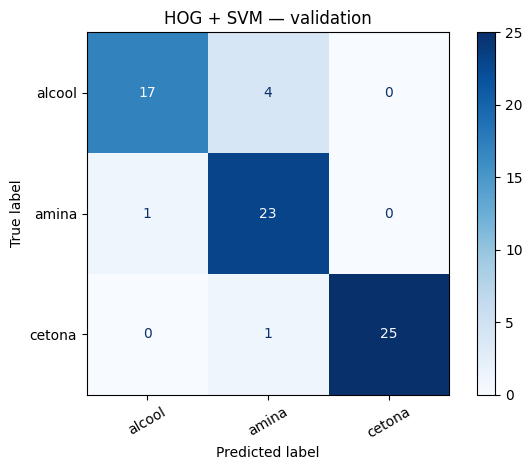


TEST
              precision    recall  f1-score   support

      alcool       0.89      0.77      0.83        22
       amina       0.78      0.88      0.82        24
      cetona       0.96      0.96      0.96        25

    accuracy                           0.87        71
   macro avg       0.88      0.87      0.87        71
weighted avg       0.88      0.87      0.87        71



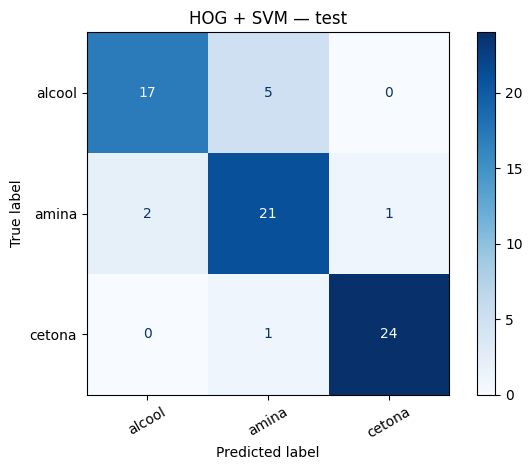


Arquivos salvos em: /content/ftir_results
Treino: 306
Validação: 71
Teste: 71


In [23]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import joblib

from pathlib import Path
from PIL import Image
from skimage.feature import hog
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

inv = pd.read_csv("data/inventory_498.csv")
BASE = Path("/content/drive/MyDrive/espectros")
SAIDA = Path("/content/ftir_results")
SAIDA.mkdir(exist_ok=True)

X, y, particoes = [], [], []

for _, r in inv.iterrows():
    particao = r["particao_historica"]

    if particao not in ("treino", "validacao", "teste"):
        continue

    caminho = BASE / r["familia_original"] / r["arquivo"]

    with Image.open(caminho) as img:
        imagem = np.array(
            img.convert("L").resize((256, 256))
        )

    X.append(hog(
        imagem,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    ))

    y.append(r["familia_original"])
    particoes.append(particao)

X = np.asarray(X)
y = np.asarray(y)
particoes = np.asarray(particoes)

treino = particoes == "treino"
validacao = particoes == "validacao"
teste = particoes == "teste"

modelo = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=0.1,
        class_weight="balanced",
        random_state=42,
        max_iter=10000
    )
)

modelo.fit(X[treino], y[treino])

metricas = {}

for nome, mascara in [
    ("validation", validacao),
    ("test", teste)
]:
    pred = modelo.predict(X[mascara])

    metricas[nome] = {
        "accuracy": float(
            accuracy_score(y[mascara], pred)
        ),
        "macro_f1": float(
            f1_score(y[mascara], pred, average="macro")
        ),
        "samples": int(mascara.sum())
    }

    print(f"\n{nome.upper()}")
    print(classification_report(
        y[mascara], pred, zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y[mascara],
        pred,
        labels=modelo.classes_,
        cmap="Blues",
        xticks_rotation=30
    )

    plt.title(f"HOG + SVM — {nome}")
    plt.tight_layout()
    plt.savefig(
        SAIDA / f"confusion_matrix_{nome}.png",
        dpi=200
    )
    plt.show()

with open(SAIDA / "metrics.json", "w") as f:
    json.dump(metricas, f, indent=2)

joblib.dump(modelo, SAIDA / "hog_svm_baseline.joblib")

print("\nArquivos salvos em:", SAIDA)
print("Treino:", treino.sum())
print("Validação:", validacao.sum())
print("Teste:", teste.sum())


In [24]:

# Identificar amostras de teste classificadas incorretamente
pred_test = modelo.predict(X[teste])

amostras_modelagem = inv[
    inv["particao_historica"].isin(
        ["treino", "validacao", "teste"]
    )
].copy()

amostras_teste = amostras_modelagem[
    amostras_modelagem["particao_historica"] == "teste"
].copy()

amostras_teste["predicted"] = pred_test
amostras_teste["correct"] = (
    amostras_teste["familia_original"]
    == amostras_teste["predicted"]
)

erros = amostras_teste[
    ~amostras_teste["correct"]
].copy()

print("Total de amostras de teste:", len(amostras_teste))
print("Classificações corretas:",
      amostras_teste["correct"].sum())
print("Erros:", len(erros))

display(erros[[
    "composto_id",
    "arquivo",
    "familia_original",
    "predicted"
]])

erros.to_csv(
    "/content/ftir_results/test_errors.csv",
    index=False
)


Total de amostras de teste: 71
Classificações corretas: 62
Erros: 9


,composto_id,arquivo,familia_original,predicted
89,beta-aminophenethyl alcohol,beta-aminophenethyl alcohol.png,alcool,amina
97,cloridrato de 2-aminoetanol,cloridrato de 2-aminoetanol..png,alcool,amina
98,cloridrato de 2-aminoetanol,cloridrato de 2-aminoetanol.png,alcool,amina
103,m-aminobenzyl alcohol,m-aminobenzyl alcohol..png,alcool,amina
109,metanol-d4,metanol-d4.png,alcool,amina
182,3-amino-1-propanol hydrochloride,3-amino-1-propanol hydrochloride.png,amina,alcool
193,9-acridinamina,9-acridinamina..png,amina,cetona
194,9-acridinamina,9-acridinamina.png,amina,alcool
302,(acetillacetonato) sódio,(acetillacetonato) sódio..png,cetona,amina


In [25]:

import pandas as pd
from pathlib import Path

erros = pd.read_csv(
    "/content/ftir_results/test_errors.csv"
)

# Identificadores selecionados a partir da revisão química
multifuncionais = {
    "betaaminophenethylalcohol",
    "cloridratode2aminoetanol",
    "maminobenzylalcohol",
    "3amino1propanolhydrochloride"
}

erros["compound_group"] = (
    erros["composto_id"].apply(normalizar_composto)
)

erros["multifunctional_candidate"] = (
    erros["compound_group"].isin(multifuncionais)
)

# Revisão química provisória, não correção
# automática das previsões
erros["error_category"] = erros[
    "multifunctional_candidate"
].map({
    True: "MULTIFUNCTIONAL_COMPOUND",
    False: "OTHER_MISCLASSIFICATION"
})

print("Erros totais:", len(erros))
print("\nCategorias de erros:")
print(erros["error_category"].value_counts())

print("\nDistribuição por classe original:")
print(erros["familia_original"].value_counts())

saida = Path(
    "/content/ftir_results/"
    "chemical_error_analysis.csv"
)

erros.to_csv(saida, index=False)

display(erros[[
    "composto_id",
    "familia_original",
    "predicted",
    "error_category"
]])


Erros totais: 9

Categorias de erros:
error_category
MULTIFUNCTIONAL_COMPOUND    5
OTHER_MISCLASSIFICATION     4
Name: count, dtype: int64

Distribuição por classe original:
familia_original
alcool    5
amina     3
cetona    1
Name: count, dtype: int64


,composto_id,familia_original,predicted,error_category
0,beta-aminophenethyl alcohol,alcool,amina,MULTIFUNCTIONAL_COMPOUND
1,cloridrato de 2-aminoetanol,alcool,amina,MULTIFUNCTIONAL_COMPOUND
2,cloridrato de 2-aminoetanol,alcool,amina,MULTIFUNCTIONAL_COMPOUND
3,m-aminobenzyl alcohol,alcool,amina,MULTIFUNCTIONAL_COMPOUND
4,metanol-d4,alcool,amina,OTHER_MISCLASSIFICATION
5,3-amino-1-propanol hydrochloride,amina,alcool,MULTIFUNCTIONAL_COMPOUND
6,9-acridinamina,amina,cetona,OTHER_MISCLASSIFICATION
7,9-acridinamina,amina,alcool,OTHER_MISCLASSIFICATION
8,(acetillacetonato) sódio,cetona,amina,OTHER_MISCLASSIFICATION


In [26]:

from pathlib import Path
import json

saida = Path("/content/ftir_results")
metricas = json.loads(
    (saida / "metrics.json").read_text()
)

relatorio = f"""# FTIR Spectral Image Classification
## Experimental HOG + Linear SVM Baseline

### Dataset
- Total FTIR images: 498
- Training images: 306
- Validation images: 71
- Test images: 71
- Images excluded pending review: 50
- Original categories: alcohol, amine, ketone

### Model
- Feature extraction: Histogram of Oriented Gradients (HOG)
- Classifier: Linear Support Vector Machine
- Input: 256 x 256 grayscale spectral images
- Evaluation: historical train/validation/test partitions

### Results
| Metric | Validation | Test |
|---|---:|---:|
| Accuracy | {metricas['validation']['accuracy']:.4f} | {metricas['test']['accuracy']:.4f} |
| Macro F1 | {metricas['validation']['macro_f1']:.4f} | {metricas['test']['macro_f1']:.4f} |

### Error Analysis
- Correct test classifications: 62/71
- Incorrect test classifications: 9/71
- Errors involving multifunctional compounds: 5
- Other misclassifications: 4

Five errors involved compounds possessing multiple
functional groups, highlighting limitations of the
original single-label classification scheme.

### Limitations
The original dataset labels represent folder categories,
not fully verified molecular functional-group annotations.

Molecular identity equivalence across dataset partitions
has not yet been exhaustively audited.

Differences in sample preparation, including KBr and
Nujol, have not yet been systematically characterized.

Therefore, these results represent a preliminary
three-category classification baseline, not validated
multi-label chemical identification.

### Future Work
- Structural validation and molecular identity auditing
- Multi-label functional-group annotation
- Evaluation of sample preparation effects
- Multi-label SVM and CNN development
"""

arquivo = saida / "BASELINE_RESULTS.md"
arquivo.write_text(relatorio, encoding="utf-8")

print("Relatório criado:", arquivo)
print("\n", relatorio)


Relatório criado: /content/ftir_results/BASELINE_RESULTS.md

 # FTIR Spectral Image Classification
## Experimental HOG + Linear SVM Baseline

### Dataset
- Total FTIR images: 498
- Training images: 306
- Validation images: 71
- Test images: 71
- Images excluded pending review: 50
- Original categories: alcohol, amine, ketone

### Model
- Feature extraction: Histogram of Oriented Gradients (HOG)
- Classifier: Linear Support Vector Machine
- Input: 256 x 256 grayscale spectral images
- Evaluation: historical train/validation/test partitions

### Results
| Metric | Validation | Test |
|---|---:|---:|
| Accuracy | 0.9155 | 0.8732 |
| Macro F1 | 0.9123 | 0.8709 |

### Error Analysis
- Correct test classifications: 62/71
- Incorrect test classifications: 9/71
- Errors involving multifunctional compounds: 5
- Other misclassifications: 4

Five errors involved compounds possessing multiple
functional groups, highlighting limitations of the
original single-label classification scheme.

### Limit

In [27]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

origem = Path("/content/ftir_results")
destino = Path("/content/FTIR_Baseline_Results.zip")

arquivos = [
    "BASELINE_RESULTS.md",
    "metrics.json",
    "confusion_matrix_validation.png",
    "confusion_matrix_test.png",
    "test_errors.csv",
    "chemical_error_analysis.csv"
]

with ZipFile(destino, "w", ZIP_DEFLATED) as zipf:
    for nome in arquivos:
        caminho = origem / nome
        if not caminho.exists():
            raise FileNotFoundError(caminho)
        zipf.write(caminho, arcname=f"results/{nome}")

print("Arquivos incluídos:", len(arquivos))
print("Pacote criado:", destino)

files.download(str(destino))


Arquivos incluídos: 6
Pacote criado: /content/FTIR_Baseline_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>